<a href="https://colab.research.google.com/github/muskankh/Satellite-vit-project/blob/main/03_finetune_vit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satellite Image Classification with Vision Transformers
## Notebook 3: Fine-Tuning a Supervised ViT (3 seeds)

**What is fine-tuning?** In Notebook 2 the pre-trained models stayed *frozen* and we trained only a tiny classifier on top. Now we **update all the weights** of a supervised Vision Transformer (`google/vit-base-patch16-224`, pre-trained on ImageNet) so it adapts to satellite images. This is the "model fine-tuning" part of the assignment.

**Procedure (designed so the results are trustworthy)**
1. Load your `split.csv` (the same split as Notebooks 1-2) and re-link the images
2. **Learning-rate search on validation only**: 3 candidate values, 1 seed
3. Train with the chosen learning rate for **3 seeds** (different random initialisation, data order, augmentation)
4. In every run keep the epoch with the best **validation** macro-F1 (early stopping on validation, never on test)
5. Evaluate on the **test set once** per seed, then report mean +/- std, bootstrap CIs and a 3-seed ensemble
6. Training curves, confusion matrix, error analysis, comparison with Notebooks 1-2
7. Save the model, predictions and results (Notebook 4 reuses them)

**Design choices (put these in your report)**
| Choice | Value | Why |
|---|---|---|
| Model | `google/vit-base-patch16-224` (86M parameters) | Standard supervised ViT, matches the assignment wording |
| Input | 224x224, model's own mean/std | Required by the model; 64x64 images are upscaled |
| Augmentation | random flips + random 90-degree rotations | Valid for aerial images (no "up"). **No colour jitter**, because colour is a key signal |
| Optimiser | AdamW, weight decay 0.01, linear warm-up (10%) then linear decay | Standard for fine-tuning transformers |
| Batch size / epochs | 32 / 4 | Enough for a 4-class task; best epoch chosen on validation |
| Precision | mixed precision (fp16) | Faster on the T4 GPU |

**Time:** roughly 3-6 minutes per run on a T4, and about 5 runs in total (3 for the learning-rate search, 2 extra seeds).

## 0. Setup

1. `Runtime -> Change runtime type -> T4 GPU`
2. Drag **`split.csv`** and **`data-2.zip`** into the Files panel (folder icon on the left). Wait for both uploads to finish.
3. Run the cells from top to bottom.

**First time? Set `QUICK_TEST = True` in the config cell.** It runs a tiny version (about 1-2 minutes) to check that everything works. Then set it back to `False` for the real run. Results from a quick test are meaningless.

In [1]:
!pip install -q transformers scikit-learn matplotlib pandas tqdm

In [2]:
import os, json, random, zipfile, shutil, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# ---------------- CONFIG ----------------
QUICK_TEST = False        # True = tiny dry run to check the code works (results are meaningless)
SEED       = 42
WORK_DIR   = Path("/content/work")
OUT_DIR    = Path("/content/outputs_nb3")
DRIVE_BACKUP_DIR = Path("/content/drive/MyDrive/satellite_project")

MODEL_NAME   = "google/vit-base-patch16-224"
EPOCHS       = 4
BATCH_SIZE   = 32
WEIGHT_DECAY = 0.01
WARMUP_FRAC  = 0.10
LR_GRID      = [1e-5, 2e-5, 5e-5]      # chosen on VALIDATION with seed 42
SEEDS        = [42, 43, 44]            # final runs
# ----------------------------------------

if QUICK_TEST:
    EPOCHS, LR_GRID, SEEDS = 1, [2e-5], [42, 43]
    print("*** QUICK TEST MODE: tiny subset, 1 epoch. Do NOT use these results in your report. ***")

FIG_DIR = OUT_DIR / "figures"
for d in (WORK_DIR, OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab - skipping Drive mount.")
print("Setup OK")

Mounted at /content/drive
Setup OK


## 1. Load `split.csv` and the images

Same loader as Notebook 2: it unzips the images again (Colab wipes its files between sessions) and re-links every row of `split.csv` by class folder and file name. We use the **identical train/val/test split**, so the fine-tuned model is compared with the earlier models on exactly the same test images.

In [3]:
SEARCH_DIRS = ["/content", "/content/outputs", "/content/drive/MyDrive",
               "/content/drive/MyDrive/satellite_project", "/content/drive/MyDrive/Colab Notebooks"]

def find_file(patterns, what):
    for folder in SEARCH_DIRS:
        f = Path(folder)
        if not f.exists():
            continue
        for pat in patterns:
            hits = sorted(f.glob(pat))
            if hits:
                print(f"Found {what}: {hits[0]}")
                return hits[0]
    raise FileNotFoundError(
        f"Could not find {what}.\n"
        "FIX: click the folder icon on the LEFT of Colab, drag the file into the Files panel, "
        "wait for the upload to finish, then re-run this cell.")

SPLIT_CSV = find_file(["split.csv", "split*.csv"], "split.csv")
ZIP_FILE  = find_file(["data-2.zip", "data*.zip"], "your image zip")

EXTRACT_DIR = WORK_DIR / "images"

# 1) Unzip into a clean folder (skip Mac junk files). Re-extract if the folder is missing or has no images.
IMG_EXT = (".jpg", ".jpeg", ".png")
def list_images(folder):
    return [p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._")]

if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)          # always start clean: stale folders from failed attempts must not be reused
EXTRACT_DIR.mkdir(parents=True)
with zipfile.ZipFile(ZIP_FILE) as z:
    keep = [m for m in z.namelist()
            if not m.startswith("__MACOSX") and "/._" not in m and not m.endswith(".DS_Store")]
    z.extractall(EXTRACT_DIR, members=keep)

files = list_images(EXTRACT_DIR)
print("Image files found after unzipping:", len(files))
if not files:
    raise FileNotFoundError("The zip contains no images. Check that you uploaded the right zip file.")

# 2) Re-link every row of split.csv to the real file, wherever the zip put it
df = pd.read_csv(SPLIT_CSV)
index   = {(p.parent.name.lower(), p.name.lower()): p for p in files}      # (class folder, file name)
by_name = {}
for p in files:
    by_name.setdefault(p.name.lower(), []).append(p)

new_paths = []
for c, p in zip(df["cls"], df["path"]):
    name = Path(p).name.lower()
    hit = index.get((str(c).lower(), name))
    if hit is None and len(by_name.get(name, [])) == 1:                    # fall back to file name alone
        hit = by_name[name][0]
    new_paths.append(str(hit) if hit is not None else None)
df["path"] = new_paths

n_missing = int(df["path"].isna().sum())
if n_missing:
    print(f"\nPROBLEM: {n_missing} of {len(df)} images from split.csv were not found in the zip.")
    print("Folders in zip      :", sorted({p.parent.name for p in files})[:10])
    print("Example zip files   :", sorted(p.name for p in files)[:5])
    print("Example split.csv   :", [Path(p).name for p in pd.read_csv(SPLIT_CSV)["path"].head(5)])
    print("Zip file used       :", ZIP_FILE, f"({Path(ZIP_FILE).stat().st_size / 1e6:.1f} MB)")
    raise AssertionError("The zip does not match split.csv. Make sure you upload the SAME data-2.zip you used in Notebook 1 "
                         "(about 25 MB, 5,631 images), and delete any other data*.zip files from the Files panel.")

CLASS_NAMES = sorted(df["cls"].unique())
y = df["label"].values
idx_train = np.where(df["split"] == "train")[0]
idx_val   = np.where(df["split"] == "val")[0]
idx_test  = np.where(df["split"] == "test")[0]
print("Classes:", CLASS_NAMES)
print(f"train={len(idx_train)}  val={len(idx_val)}  test={len(idx_test)}   (Notebook 1 gave 3942 / 846 / 843)")
df[["cls", "split"]].value_counts().unstack()

Found split.csv: /content/drive/MyDrive/satellite_project/split.csv
Found your image zip: /content/drive/MyDrive/data-2.zip
Image files found after unzipping: 5631
Classes: ['cloudy', 'desert', 'green_area', 'water']
train=3942  val=846  test=843   (Notebook 1 gave 3942 / 846 / 843)


split,test,train,val
cls,,,
cloudy,225,1050,225
desert,170,788,173
green_area,225,1050,225
water,223,1054,223


In [4]:
if QUICK_TEST:
    rs = np.random.RandomState(SEED)
    idx_train = rs.choice(idx_train, 256, replace=False)
    idx_val   = rs.choice(idx_val, 128, replace=False)
    idx_test  = rs.choice(idx_test, 128, replace=False)
    print(f"QUICK TEST subset: train={len(idx_train)} val={len(idx_val)} test={len(idx_test)}")

y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
id2label = {i: c for i, c in enumerate(CLASS_NAMES)}
label2id = {c: i for i, c in enumerate(CLASS_NAMES)}

## 2. Data pipeline

- **Resize** every image to 224x224 (bicubic) and **normalise** with the model's own mean/std. The 64x64 images are upscaled 3.5x and look blurry, so mention this in your report.
- **Training augmentation:** random horizontal flip, vertical flip and 0/90/180/270-degree rotation. We deliberately avoid colour changes, since colour is one of the most informative cues.
- **Validation/test:** only resize and normalise (no randomness).

Device: cuda | Tesla T4


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

Normalisation mean/std: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)
Batch tensor: (32, 3, 224, 224) | labels: [1, 1, 2, 2, 3, 0, 2, 3]


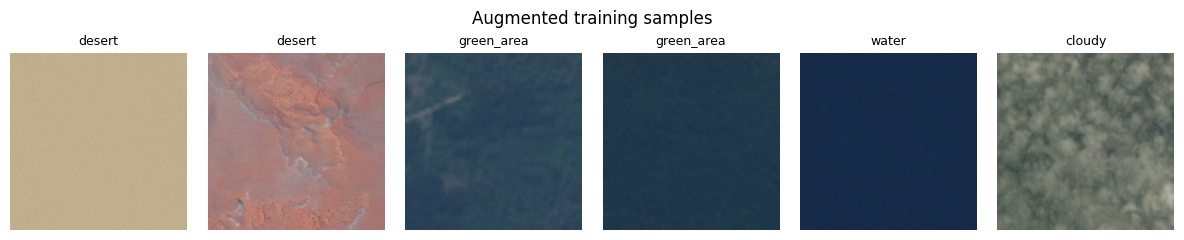

In [5]:
# [needs-torch]
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModelForImageClassification, AutoImageProcessor, get_linear_schedule_with_warmup

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
print("Device:", DEVICE, "|", GPU_NAME)
if DEVICE == "cpu":
    print("WARNING: no GPU found. Use Runtime -> Change runtime type -> T4 GPU. Training on CPU would take hours.")

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
MEAN, STD = processor.image_mean, processor.image_std
print("Normalisation mean/std:", MEAN, STD)

class RandomRot90:
    """Rotate by a random multiple of 90 degrees (exact for square images)."""
    def __call__(self, img):
        k = random.randint(0, 3)
        return img.rotate(90 * k) if k else img

train_tf = T.Compose([RandomRot90(), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                      T.Resize((224, 224), interpolation=T.InterpolationMode.BICUBIC),
                      T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf  = T.Compose([T.Resize((224, 224), interpolation=T.InterpolationMode.BICUBIC),
                      T.ToTensor(), T.Normalize(MEAN, STD)])

class SatDataset(Dataset):
    def __init__(self, indices, train):
        self.idx, self.train = np.asarray(indices), train
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        img = Image.open(df.loc[j, "path"]).convert("RGB")
        return (train_tf if self.train else eval_tf)(img), int(y[j])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loader(indices, train, seed):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(SatDataset(indices, train), batch_size=BATCH_SIZE if train else 64, shuffle=train,
                      num_workers=2, pin_memory=(DEVICE == "cuda"), worker_init_fn=seed_worker, generator=g,
                      drop_last=False)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

# Quick look at one augmented batch (sanity check)
xb, yb = next(iter(make_loader(idx_train, True, SEED)))
print("Batch tensor:", tuple(xb.shape), "| labels:", yb[:8].tolist())
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, x_, l_ in zip(axes, xb[:6], yb[:6]):
    img_ = (x_ * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1)
    ax.imshow(img_.permute(1, 2, 0).numpy()); ax.set_title(CLASS_NAMES[l_], fontsize=9); ax.axis("off")
plt.suptitle("Augmented training samples"); plt.tight_layout()
plt.savefig(FIG_DIR / "13_augmented_samples.png", dpi=150); plt.show()

## 3. Training and evaluation functions

`train_one(seed, lr)` trains the model for a few epochs. After **every epoch** it measures validation loss, accuracy and macro-F1, and remembers the weights of the best epoch (by validation macro-F1). At the end those best weights are restored. The test set is **not touched** here.

In [6]:
# [needs-torch]
def build_model():
    return AutoModelForImageClassification.from_pretrained(
        MODEL_NAME, num_labels=len(CLASS_NAMES), id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True).to(DEVICE)          # new 4-class head replaces the 1000-class ImageNet head

@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    out = []
    for xb, _ in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
            out.append(model(pixel_values=xb.to(DEVICE)).logits.float().cpu())
    return torch.cat(out).numpy()

def train_one(seed, lr, epochs=EPOCHS, verbose=True):
    t0 = time.time()
    set_seed(seed)
    model = build_model()
    train_loader = make_loader(idx_train, True, seed)
    val_loader   = make_loader(idx_val, False, seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    total = epochs * len(train_loader)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history, best_f1, best_epoch, best_state = [], -1.0, -1, None
    for ep in range(1, epochs + 1):
        model.train()
        tot_loss, correct, n = 0.0, 0, 0
        for xb, yb in tqdm(train_loader, desc=f"seed {seed} lr {lr:g} epoch {ep}/{epochs}", leave=False):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
                logits = model(pixel_values=xb).logits
            loss = F.cross_entropy(logits.float(), yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot_loss += loss.item() * len(yb); correct += (logits.argmax(1) == yb).sum().item(); n += len(yb)

        val_logits = predict_logits(model, val_loader)
        val_pred = val_logits.argmax(1)
        val_loss = F.cross_entropy(torch.tensor(val_logits), torch.tensor(y_val)).item()
        rec = dict(epoch=ep, train_loss=tot_loss / n, train_acc=correct / n, val_loss=val_loss,
                   val_acc=accuracy_score(y_val, val_pred), val_macro_f1=f1_score(y_val, val_pred, average="macro"))
        history.append(rec)
        if verbose:
            print(f"  seed {seed} lr {lr:g} | epoch {ep}: train_loss {rec['train_loss']:.4f} train_acc {rec['train_acc']:.4f} "
                  f"| val_loss {rec['val_loss']:.4f} val_acc {rec['val_acc']:.4f} val_F1 {rec['val_macro_f1']:.4f}")
        if rec["val_macro_f1"] > best_f1:
            best_f1, best_epoch = rec["val_macro_f1"], ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    del model, opt, scaler
    torch.cuda.empty_cache()
    return dict(seed=seed, lr=lr, history=history, best_val_f1=best_f1, best_epoch=best_epoch,
                state=best_state, seconds=time.time() - t0)
print("Training functions ready")

Training functions ready


## 4. Choose the learning rate (validation only)

We try 3 learning rates with seed 42 and keep the one with the best validation macro-F1.
The winning run is reused as the first of our 3 seeds, so no training is wasted.

**Limitation to mention in the report:** the search uses one seed and a small grid.

In [7]:
# [needs-torch]
# Fallback definition if the configuration cell wasn't run
if 'LR_GRID' not in globals():
    LR_GRID = [1e-5, 2e-5, 5e-5]

lr_runs = []
for lr in LR_GRID:
    print(f"\n=== Learning rate {lr:g} ===")
    r = train_one(42, lr)
    lr_runs.append(r)
    print(f"  -> best epoch {r['best_epoch']}, best validation macro-F1 {r['best_val_f1']:.4f}  ({r['seconds']/60:.1f} min)")

best_run = max(lr_runs, key=lambda r: r["best_val_f1"])
BEST_LR = best_run["lr"]
LR_TABLE = pd.DataFrame([dict(lr=r["lr"], best_epoch=r["best_epoch"], val_macro_f1=r["best_val_f1"],
                              final_epoch_val_f1=r["history"][-1]["val_macro_f1"], minutes=r["seconds"] / 60) for r in lr_runs])
print("\nLearning-rate search (validation):")
print(LR_TABLE.round(4).to_string(index=False))
print("CHOSEN learning rate:", BEST_LR)


=== Learning rate 1e-05 ===


[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

...

seed 42 lr 5e-05 epoch 3/4:   0%|          | 0/124 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78c1acd400e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78c1acd400e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  seed 42 lr 5e-05 | epoch 3: train_loss 0.0034 train_acc 0.9992 | val_loss 0.0121 val_acc 0.9976 val_F1 0.9978


seed 42 lr 5e-05 epoch 4/4:   0%|          | 0/124 [00:00<?, ?it/s]

  seed 42 lr 5e-05 | epoch 4: train_loss 0.0003 train_acc 1.0000 | val_loss 0.0087 val_acc 0.9988 val_F1 0.9989
  -> best epoch 4, best validation macro-F1 0.9989  (3.2 min)

Learning-rate search (validation):
 lr  best_epoch  val_macro_f1  final_epoch_val_f1  minutes
0.0           1        0.9989              0.9978   3.0513
0.0           1        0.9989              0.9989   3.4625
0.0           4        0.9989              0.9989   3.2369
CHOSEN learning rate: 1e-05


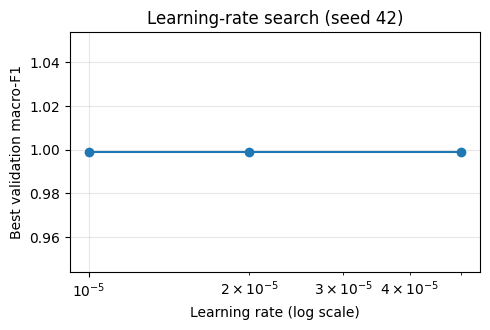

In [8]:
LR_TABLE.to_csv(OUT_DIR / "lr_search_validation.csv", index=False)
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(LR_TABLE["lr"], LR_TABLE["val_macro_f1"], marker="o")
ax.set_xscale("log"); ax.set_xlabel("Learning rate (log scale)"); ax.set_ylabel("Best validation macro-F1")
ax.set_title("Learning-rate search (seed 42)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "14_lr_search.png", dpi=150); plt.show()

## 5. Train with 3 seeds

A **seed** controls the random initialisation of the new classification head, the order of the training data and the random augmentations. Repeating with different seeds shows whether the result is stable. Report the **mean +/- standard deviation**, not your luckiest run.

In [9]:
# [needs-torch]
runs = {42: best_run}                      # reuse the winning learning-rate run as seed 42
for s in SEEDS:
    if s in runs:
        continue
    print(f"\n=== Seed {s}, learning rate {BEST_LR:g} ===")
    runs[s] = train_one(s, BEST_LR)
    print(f"  -> best epoch {runs[s]['best_epoch']}, best validation macro-F1 {runs[s]['best_val_f1']:.4f}  ({runs[s]['seconds']/60:.1f} min)")
print("\nAll training finished.")

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.



=== Seed 43, learning rate 1e-05 ===


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([4])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([4, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


seed 43 lr 1e-05 epoch 1/4:   0%|          | 0/124 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78c1acd400e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78c1acd400e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  seed 44 lr 1e-05 | epoch 3: train_loss 0.0038 train_acc 0.9995 | val_loss 0.0101 val_acc 0.9976 val_F1 0.9978


seed 44 lr 1e-05 epoch 4/4:   0%|          | 0/124 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78c1acd400e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x78c1acd400e0>
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    Traceback (most recent call last):
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    self._shutdown_workers()    assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
AssertionError: can only test a child process    
if w.is_alive():
  File "/usr/lib/

  seed 44 lr 1e-05 | epoch 4: train_loss 0.0014 train_acc 1.0000 | val_loss 0.0117 val_acc 0.9976 val_F1 0.9978
  -> best epoch 2, best validation macro-F1 0.9978  (3.4 min)

All training finished.


## 6. Final test evaluation (once per seed)

Every run now predicts the test set **one time**, using its best-validation-epoch weights. Nothing is tuned after this point.

In [10]:
# [needs-torch]
test_loader = make_loader(idx_test, False, SEED)
TEST_LOGITS = {}
for s in SEEDS:
    m = build_model()
    m.load_state_dict(runs[s]["state"])
    TEST_LOGITS[s] = predict_logits(m, test_loader)
    del m; torch.cuda.empty_cache()
    print(f"seed {s}: test predictions done")

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([4])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([4, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


seed 42: test predictions done


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([4])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([4, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


seed 43: test predictions done


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([4])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([4, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


seed 44: test predictions done


## 7. Results

**Metrics:** accuracy, macro-F1 (each class counts equally), 95% bootstrap confidence intervals (1,000 resamples of the test set), and mean +/- std over seeds. We also report a **3-seed ensemble** (average of the three models' probabilities), which usually gives a small boost.

In [11]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def macro_f1(a, b):
    return f1_score(a, b, average="macro")

def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    s = [metric(y_true[ix], y_pred[ix]) for ix in (rng.randint(0, n, n) for _ in range(n_boot))]
    return np.percentile(s, [2.5, 97.5])

PROBS = {s: softmax(TEST_LOGITS[s]) for s in SEEDS}
PRED  = {s: PROBS[s].argmax(1) for s in SEEDS}
ENS_PROB = np.mean([PROBS[s] for s in SEEDS], axis=0)
PRED["ensemble"] = ENS_PROB.argmax(1)

rows = []
for s in SEEDS + ["ensemble"]:
    p = PRED[s]
    acc_ci = bootstrap_ci(y_test, p, accuracy_score)
    f1_ci = bootstrap_ci(y_test, p, macro_f1)
    rows.append(dict(run=f"seed {s}" if s != "ensemble" else "3-seed ensemble",
                     best_epoch=runs[s]["best_epoch"] if s != "ensemble" else "-",
                     val_macro_f1=runs[s]["best_val_f1"] if s != "ensemble" else np.nan,
                     test_acc=accuracy_score(y_test, p), test_acc_lo=acc_ci[0], test_acc_hi=acc_ci[1],
                     test_macro_f1=macro_f1(y_test, p), test_f1_lo=f1_ci[0], test_f1_hi=f1_ci[1]))
res = pd.DataFrame(rows)
print(f"Fine-tuned {MODEL_NAME}, learning rate {BEST_LR:g}, {EPOCHS} epochs, test set n = {len(y_test)}\n")
print(res.round(4).to_string(index=False))

accs = np.array([accuracy_score(y_test, PRED[s]) for s in SEEDS])
f1s  = np.array([macro_f1(y_test, PRED[s]) for s in SEEDS])
print(f"\nMEAN +/- STD over {len(SEEDS)} seeds:  accuracy {accs.mean():.4f} +/- {accs.std(ddof=1) if len(SEEDS) > 1 else 0:.4f}"
      f"   macro-F1 {f1s.mean():.4f} +/- {f1s.std(ddof=1) if len(SEEDS) > 1 else 0:.4f}")

# The "headline" run is chosen by VALIDATION score (never by test score)
BEST_SEED = max(SEEDS, key=lambda s: runs[s]["best_val_f1"])
print("Best seed by validation macro-F1:", BEST_SEED)

Fine-tuned google/vit-base-patch16-224, learning rate 1e-05, 4 epochs, test set n = 843

            run best_epoch  val_macro_f1  test_acc  test_acc_lo  test_acc_hi  test_macro_f1  test_f1_lo  test_f1_hi
        seed 42          1        0.9989    0.9988       0.9964          1.0         0.9989      0.9965         1.0
        seed 43          2        0.9989    1.0000       1.0000          1.0         1.0000      1.0000         1.0
        seed 44          2        0.9978    1.0000       1.0000          1.0         1.0000      1.0000         1.0
3-seed ensemble          -           NaN    1.0000       1.0000          1.0         1.0000      1.0000         1.0

MEAN +/- STD over 3 seeds:  accuracy 0.9996 +/- 0.0007   macro-F1 0.9996 +/- 0.0006
Best seed by validation macro-F1: 42


### 7.1 Training curves
Look for: validation loss that stops improving or rises while training loss keeps falling (overfitting), and which epoch was selected.

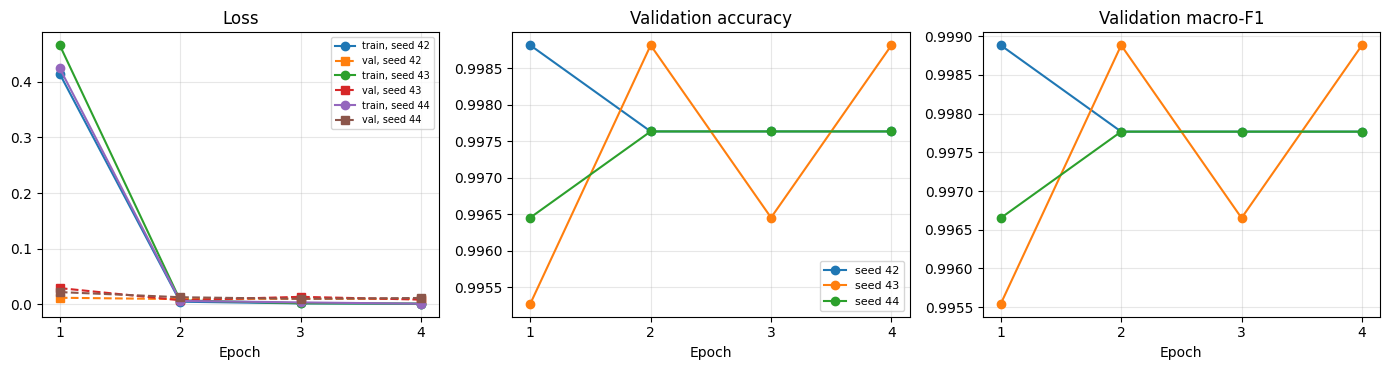

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for s in SEEDS:
    h = pd.DataFrame(runs[s]["history"])
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=f"train, seed {s}")
    axes[0].plot(h["epoch"], h["val_loss"], marker="s", ls="--", label=f"val, seed {s}")
    axes[1].plot(h["epoch"], h["val_acc"], marker="o", label=f"seed {s}")
    axes[2].plot(h["epoch"], h["val_macro_f1"], marker="o", label=f"seed {s}")
axes[0].set_title("Loss"); axes[1].set_title("Validation accuracy"); axes[2].set_title("Validation macro-F1")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.set_xticks(range(1, EPOCHS + 1))
axes[0].legend(fontsize=7); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "15_training_curves.png", dpi=150); plt.show()

hist_all = pd.concat([pd.DataFrame(runs[s]["history"]).assign(seed=s) for s in SEEDS])
hist_all.to_csv(OUT_DIR / "training_history.csv", index=False)

### 7.2 Comparison with Notebooks 1 and 2
We load the earlier results if the JSON files are available. The colour-only (82.4%) and image-size-only (53.3%) baselines come from Notebook 1 and were computed on a separate random split, so treat them as reference lines, not exact test numbers.

Loaded Notebook 2 results from /content/drive/MyDrive/satellite_project/outputs_nb2/results_notebook2.json
                          method    acc     lo     hi
                  Zero-shot CLIP 0.7461 0.7153 0.7758
      Linear probe CLIP ViT-B/32 0.9988 0.9953 1.0000
    Linear probe DINOv2 ViT-B/14 0.9964 0.9917 1.0000
        Fine-tuned ViT (seed 42) 0.9988 0.9964 1.0000
Fine-tuned ViT (3-seed ensemble) 1.0000 1.0000 1.0000


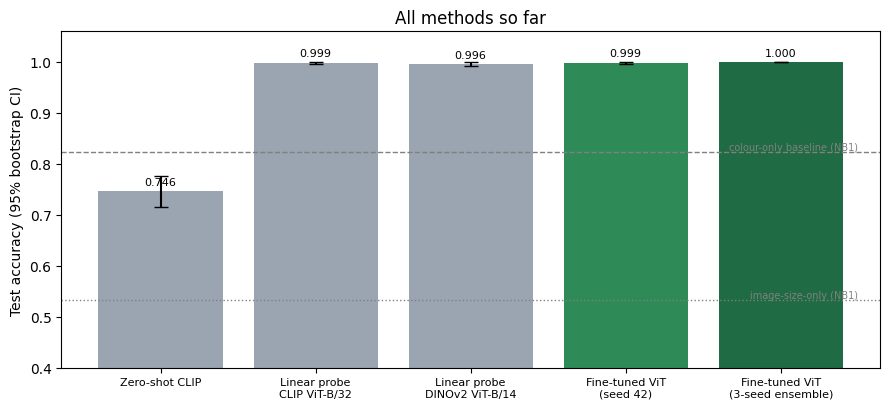

In [13]:
nb2_res = None
for folder in ["/content/outputs_nb2", "/content", "/content/drive/MyDrive/satellite_project/outputs_nb2",
               "/content/drive/MyDrive/satellite_project", "/content/outputs"]:
    jf = Path(folder) / "results_notebook2.json"
    if jf.exists():
        nb2_res = json.load(open(jf)); print("Loaded Notebook 2 results from", jf); break
if nb2_res is None:
    print("results_notebook2.json not found - showing only Notebook 3 results. (Upload it to the Files panel to add the comparison.)")

best_p = PRED[BEST_SEED]
vit_ci = bootstrap_ci(y_test, best_p, accuracy_score)
comp = []
if nb2_res:
    zs = nb2_res["zero_shot_clip_from_notebook1"]
    comp.append(("Zero-shot CLIP", zs["acc"], zs["acc_lo"], zs["acc_hi"]))
    for name, r in nb2_res["probes"].items():
        comp.append((f"Linear probe\n{name}", r["test_accuracy"], *r["test_accuracy_ci95"]))
comp.append((f"Fine-tuned ViT\n(seed {BEST_SEED})", accuracy_score(y_test, best_p), *vit_ci))
comp.append(("Fine-tuned ViT\n(3-seed ensemble)", accuracy_score(y_test, PRED["ensemble"]), *bootstrap_ci(y_test, PRED["ensemble"], accuracy_score)))

cdf = pd.DataFrame(comp, columns=["method", "acc", "lo", "hi"])
print(cdf.assign(method=cdf["method"].str.replace("\n", " ")).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(cdf))
ax.bar(x, cdf["acc"], yerr=[cdf["acc"] - cdf["lo"], cdf["hi"] - cdf["acc"]], capsize=5,
       color=["#9aa5b1"] * (len(cdf) - 2) + ["#2e8b57", "#1f6b43"])
for xi, a in zip(x, cdf["acc"]):
    ax.text(xi, a + 0.012, f"{a:.3f}", ha="center", fontsize=8)
ax.axhline(0.824, ls="--", color="grey", lw=1); ax.text(len(x) - 0.5, 0.828, "colour-only baseline (NB1)", ha="right", fontsize=7, color="grey")
ax.axhline(0.533, ls=":", color="grey", lw=1);  ax.text(len(x) - 0.5, 0.537, "image-size-only (NB1)", ha="right", fontsize=7, color="grey")
ax.set_xticks(x); ax.set_xticklabels(cdf["method"], fontsize=8)
ax.set_ylim(0.4, 1.06); ax.set_ylabel("Test accuracy (95% bootstrap CI)")
ax.set_title("All methods so far")
plt.tight_layout(); plt.savefig(FIG_DIR / "16_all_methods.png", dpi=150); plt.show()

### 7.3 Per-class results and confusion matrix
Which classes does the fine-tuned model still confuse? Compare with the confusion matrices from Notebooks 1 and 2.

===== Fine-tuned ViT, seed 42 (best validation) =====
              precision    recall  f1-score   support

      cloudy      1.000     1.000     1.000       225
      desert      1.000     1.000     1.000       170
  green_area      0.996     1.000     0.998       225
       water      1.000     0.996     0.998       223

    accuracy                          0.999       843
   macro avg      0.999     0.999     0.999       843
weighted avg      0.999     0.999     0.999       843



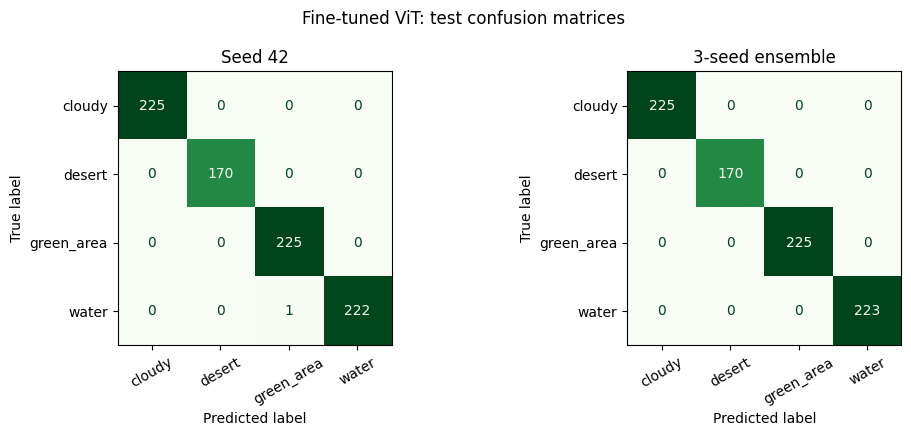

In [14]:
print(f"===== Fine-tuned ViT, seed {BEST_SEED} (best validation) =====")
print(classification_report(y_test, PRED[BEST_SEED], target_names=CLASS_NAMES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for ax, key, title in ((axes[0], BEST_SEED, f"Seed {BEST_SEED}"), (axes[1], "ensemble", "3-seed ensemble")):
    cm = confusion_matrix(y_test, PRED[key])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Greens", colorbar=False, xticks_rotation=30)
    ax.set_title(title)
plt.suptitle("Fine-tuned ViT: test confusion matrices"); plt.tight_layout()
plt.savefig(FIG_DIR / "17_vit_confusion.png", dpi=150); plt.show()

## 8. Error analysis

**Your task:** categorise 30-50 errors by hand and write the counts in your report (ambiguous scene, dark or blurry image, label looks wrong, genuine model failure).
We also check whether errors cluster in one image size, which is an early hint about the resolution shortcut (the formal test is in Notebook 4).

Seed 42: 1 errors out of 843 (0.12%)

Most frequent confusions (true -> predicted):
  water      -> green_area 1

Errors made by ALL seeds: 0 | by ANY seed: 1  (errors shared by every seed are more likely hard images or label noise)


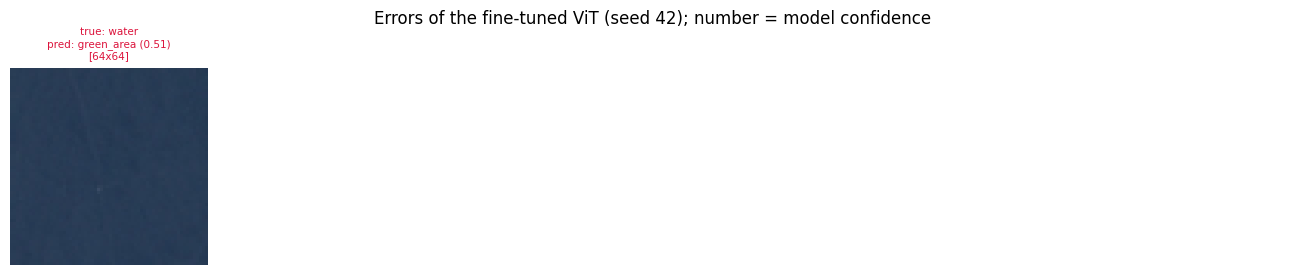


Error rate by image size (test set):
         error_rate  n_errors  n_images
size                                   
256x256      0.0000         0       395
64x64        0.0022         1       448


In [15]:
pred = PRED[BEST_SEED]
wrong_pos = np.where(pred != y_test)[0]
print(f"Seed {BEST_SEED}: {len(wrong_pos)} errors out of {len(y_test)} ({100 * len(wrong_pos) / len(y_test):.2f}%)")

cm = confusion_matrix(y_test, pred)
pairs = sorted([(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j] > 0],
               key=lambda t: -t[2])
print("\nMost frequent confusions (true -> predicted):")
for t, p_, n in pairs[:5]:
    print(f"  {t:10s} -> {p_:10s} {n}")

# Do the 3 seeds make the same mistakes?
all_wrong = [set(np.where(PRED[s] != y_test)[0]) for s in SEEDS]
print(f"\nErrors made by ALL seeds: {len(set.intersection(*all_wrong))} | by ANY seed: {len(set.union(*all_wrong))}"
      "  (errors shared by every seed are more likely hard images or label noise)")

if len(wrong_pos):
    pick = np.random.RandomState(SEED).choice(wrong_pos, min(18, len(wrong_pos)), replace=False)
    cols = 6; rws = int(np.ceil(len(pick) / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(2.2 * cols, 2.7 * rws))
    axes = np.atleast_1d(axes).flatten()
    for ax in axes: ax.axis("off")
    for ax, k in zip(axes, pick):
        i = idx_test[k]
        ax.imshow(Image.open(df.loc[i, "path"]).convert("RGB"))
        conf = PROBS[BEST_SEED][k].max()
        ax.set_title(f"true: {df.loc[i, 'cls']}\npred: {CLASS_NAMES[pred[k]]} ({conf:.2f})\n[{df.loc[i, 'size']}]", fontsize=7.5, color="crimson")
    plt.suptitle(f"Errors of the fine-tuned ViT (seed {BEST_SEED}); number = model confidence", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / "18_vit_errors.png", dpi=150); plt.show()

err_size = pd.DataFrame({"size": df.loc[idx_test, "size"].values, "wrong": pred != y_test}).groupby("size")["wrong"].agg(["mean", "sum", "count"])
err_size.columns = ["error_rate", "n_errors", "n_images"]
print("\nError rate by image size (test set):")
print(err_size.round(4))

## 9. Compute cost (for your ethics section)

Report the hardware and time. A rough energy estimate makes the environmental-impact paragraph concrete.

In [16]:
total_sec = sum(r["seconds"] for r in lr_runs) + sum(runs[s]["seconds"] for s in SEEDS if runs[s] is not best_run)
hours = total_sec / 3600
n_params = 85.8   # ViT-B/16 with a 4-class head (about 86 million parameters)
print(f"Hardware: {GPU_NAME}")
print(f"Total training time (LR search + seeds): {total_sec / 60:.1f} minutes = {hours:.2f} GPU-hours")
print(f"Rough energy upper bound at the T4's 70 W board power: {0.070 * hours:.3f} kWh (excludes CPU, cooling and data-centre overhead)")
print(f"Trainable parameters: about {n_params:.0f} million")

Hardware: Tesla T4
Total training time (LR search + seeds): 16.3 minutes = 0.27 GPU-hours
Rough energy upper bound at the T4's 70 W board power: 0.019 kWh (excludes CPU, cooling and data-centre overhead)
Trainable parameters: about 86 million


## 10. Save everything

Saved for later notebooks: the **best model** (chosen by validation score), the **test predictions of every seed** (Notebook 4 uses them for paired statistical tests and the robustness comparison), the results JSON and the training history. Everything is also copied to Google Drive, because Colab deletes its files when the session ends.

In [17]:
# [needs-torch]
MODEL_DIR = OUT_DIR / "vit_best_model"
m = build_model(); m.load_state_dict(runs[BEST_SEED]["state"])
m.save_pretrained(MODEL_DIR); processor.save_pretrained(MODEL_DIR)
del m; torch.cuda.empty_cache()
print("Saved best model (seed %d) to %s" % (BEST_SEED, MODEL_DIR))

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([4])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([4, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best model (seed 42) to /content/outputs_nb3/vit_best_model


In [18]:
preds_df = df.loc[idx_test, ["path", "cls", "label", "size"]].reset_index(drop=True)
for s in SEEDS:
    preds_df[f"pred_seed{s}"] = PRED[s]
preds_df["pred_ensemble"] = PRED["ensemble"]
for k, c in enumerate(CLASS_NAMES):
    preds_df[f"prob_ens_{c}"] = ENS_PROB[:, k]
preds_df.to_csv(OUT_DIR / "vit_test_predictions.csv", index=False)

results = {
    "quick_test": bool(QUICK_TEST),
    "model": MODEL_NAME, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "weight_decay": WEIGHT_DECAY,
    "warmup_fraction": WARMUP_FRAC, "chosen_lr": float(BEST_LR), "seeds": SEEDS, "best_seed_by_val": int(BEST_SEED),
    "lr_search_val_macro_f1": {f"{r['lr']:g}": float(r["best_val_f1"]) for r in lr_runs},
    "per_seed": {str(s): {"best_epoch": int(runs[s]["best_epoch"]), "val_macro_f1": float(runs[s]["best_val_f1"]),
                          "test_accuracy": float(accuracy_score(y_test, PRED[s])),
                          "test_macro_f1": float(macro_f1(y_test, PRED[s]))} for s in SEEDS},
    "mean_test_accuracy": float(accs.mean()), "std_test_accuracy": float(accs.std(ddof=1)) if len(SEEDS) > 1 else 0.0,
    "mean_test_macro_f1": float(f1s.mean()), "std_test_macro_f1": float(f1s.std(ddof=1)) if len(SEEDS) > 1 else 0.0,
    "best_seed_test_accuracy_ci95": [float(v) for v in vit_ci],
    "ensemble_test_accuracy": float(accuracy_score(y_test, PRED["ensemble"])),
    "ensemble_test_macro_f1": float(macro_f1(y_test, PRED["ensemble"])),
    "n_test": int(len(y_test)),
    "compute": {"gpu": GPU_NAME, "gpu_hours": float(hours), "energy_kwh_upper_bound_gpu_only": float(0.070 * hours)},
}
with open(OUT_DIR / "results_notebook3.json", "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

try:
    DRIVE_BACKUP_DIR.mkdir(parents=True, exist_ok=True)
    shutil.copytree(OUT_DIR, DRIVE_BACKUP_DIR / "outputs_nb3", dirs_exist_ok=True)
    print("\nBacked up to Google Drive:", DRIVE_BACKUP_DIR / "outputs_nb3")
except Exception as e:
    print("\nDrive backup skipped:", e)
shutil.make_archive("/content/notebook3_outputs", "zip", OUT_DIR)
print("Also created /content/notebook3_outputs.zip (download from the Files panel).")
if QUICK_TEST:
    print("\n*** QUICK TEST finished: the code works. Now set QUICK_TEST = False in the config cell and run everything again. ***")

{
  "quick_test": false,
  "model": "google/vit-base-patch16-224",
  "epochs": 4,
  "batch_size": 32,
  "weight_decay": 0.01,
  "warmup_fraction": 0.1,
  "chosen_lr": 1e-05,
  "seeds": [
    42,
    43,
    44
  ],
  "best_seed_by_val": 42,
  "lr_search_val_macro_f1": {
    "1e-05": 0.9988839230106177,
    "2e-05": 0.9988839230106177,
    "5e-05": 0.9988839230106177
  },
  "per_seed": {
    "42": {
      "best_epoch": 1,
      "val_macro_f1": 0.9988839230106177,
      "test_accuracy": 0.9988137603795967,
      "test_macro_f1": 0.9988838785221357
    },
    "43": {
      "best_epoch": 2,
      "val_macro_f1": 0.9988839230106177,
      "test_accuracy": 1.0,
      "test_macro_f1": 1.0
    },
    "44": {
      "best_epoch": 2,
      "val_macro_f1": 0.9977678571428572,
      "test_accuracy": 1.0,
      "test_macro_f1": 1.0
    }
  },
  "mean_test_accuracy": 0.999604586793199,
  "std_test_accuracy": 0.000684875764163255,
  "mean_test_macro_f1": 0.9996279595073786,
  "std_test_macro_f1": 0.00